# 2. Indicadores de produção

> ⚠️ **Os dados deste projeto são SIMULADOS** (ver notebook 01). Não são registos de nenhuma exploração.

Neste notebook calculamos, a partir das biometrias guardadas em `data/raw/registos_simulados.csv`, os quatro indicadores mais usados para acompanhar um ciclo de engorda:

| Indicador | O que responde |
|---|---|
| **SGR**: taxa de crescimento específica (%/dia) | A que ritmo cresce o peixe, em proporção ao seu peso? |
| **GPD**: ganho de peso diário (g/dia) | Quantos gramas ganha o peixe por dia? |
| **FCR**: índice de conversão alimentar | Quantos kg de ração são precisos para produzir 1 kg de peixe? |
| **Sobrevivência** (%) | Que percentagem dos peixes chega ao fim? |

As funções estão em `src/indicators.py`, para poderem ser usadas noutros notebooks ou com dados reais.

In [1]:
import sys
sys.path.append("..")   # para o Python encontrar a pasta src/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.dados import ler_registos
from src.indicators import (sgr, gpd, fcr, sobrevivencia, biomassa_kg,
                            agrupar_biometrias, indicadores_por_periodo, resumo_ciclo)
from src.growth import PARAMETROS

sns.set_theme(style="whitegrid", context="notebook")
CORES = {"dourada": "#c9971c", "robalo": "#3f6ea6"}
NOMES = {"dourada": "Dourada (Sparus aurata)", "robalo": "Robalo (Dicentrarchus labrax)"}
ESPECIES = ["dourada", "robalo"]

In [2]:
# Para usar dados reais, basta trocar o caminho por um CSV com as mesmas colunas
registos = ler_registos("../data/raw/registos_simulados.csv")
registos.head()

,especie,dia,data,peso_medio_g,temperatura_c,racao_kg,n_peixes
0,dourada,0,2024-04-01,3.1,16.2,0.0,4998
1,dourada,14,2024-04-15,5.0,16.6,19.3,4955
2,dourada,28,2024-04-29,7.4,17.4,23.9,4923
3,dourada,42,2024-05-13,10.2,18.3,30.8,4884
4,dourada,56,2024-05-27,14.7,19.3,38.9,4855


## 2.1 As fórmulas

Em todas as fórmulas, $W_i$ e $W_f$ são o peso médio (g) no início e no fim de um período, e $t$ é a duração do período em dias.

### Taxa de crescimento específica (SGR)

$$SGR = \frac{\ln W_f - \ln W_i}{t} \times 100 \quad (\%/\text{dia})$$

É a percentagem do seu peso que o peixe ganha por dia. Usa logaritmos porque o crescimento é **multiplicativo**: um peixe de 10 g que ganha 1 g cresceu 10 %, mas um de 300 g que ganha 1 g cresceu só 0,3 %. A SGR permite comparar peixes de tamanhos diferentes e é o indicador mais usado em ensaios de nutrição.

### Ganho de peso diário (GPD)

$$GPD = \frac{W_f - W_i}{t} \quad (\text{g/dia})$$

É o ganho em gramas por dia. É mais intuitivo do que a SGR, mas depende muito do tamanho: peixes grandes ganham mais gramas por dia, mesmo crescendo menos em proporção.

### Índice de conversão alimentar (FCR, *feed conversion ratio*)

$$FCR = \frac{\text{ração dada (kg)}}{B_f - B_i \ \ (\text{kg})} \qquad B = \frac{W \times N}{1000}$$

$B$ é a biomassa da jaula (peso médio × número de peixes vivos, em kg). Um FCR de 2 quer dizer que foram precisos 2 kg de ração para produzir 1 kg de peixe. Quanto **mais baixo**, melhor. A ração é o maior custo de uma exploração, por isso este é o indicador com mais peso económico.

Como usamos a biomassa dos peixes **vivos**, este é o FCR **económico**: a ração comida pelos peixes que morreram entra na conta, mas a biomassa deles não. É sempre um pouco mais alto do que o FCR biológico.

### Sobrevivência

$$\text{Sobrevivência} = \frac{N_f}{N_i} \times 100 \quad (\%)$$

$N_i$ e $N_f$ são o número de peixes no início e no fim.

In [3]:
# Exemplo com números redondos: um peixe passa de 100 g para 130 g em 30 dias
print(f"SGR = {sgr(100, 130, 30):.2f} %/dia")
print(f"GPD = {gpd(100, 130, 30):.2f} g/dia")
# Uma jaula passa de 500 kg para 650 kg de biomassa com 300 kg de ração
print(f"FCR = {fcr(300, 500, 650):.2f}")
# 5000 peixes no início e 4600 no fim
print(f"Sobrevivência = {sobrevivencia(5000, 4600):.1f} %")

SGR = 0.87 %/dia
GPD = 1.00 g/dia
FCR = 2.00
Sobrevivência = 92.0 %


## 2.2 Indicadores do ciclo completo

Calculamos os indicadores entre a primeira biometria e dois momentos:
- **dia 448** (≈ 15 meses), quando a dourada está perto dos 400 g;
- **dia 630**, a última biometria.

In [4]:
linhas = []
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    for ate_dia in [448, 630]:
        r = resumo_ciclo(reg, ate_dia=ate_dia)
        linhas.append({
            "espécie": especie,
            "até ao dia": ate_dia,
            "peso final (g)": round(r["peso_final_g"]),
            "SGR (%/dia)": round(r["sgr"], 2),
            "GPD (g/dia)": round(r["gpd"], 2),
            "FCR": round(r["fcr"], 2),
            "sobrevivência (%)": round(r["sobrevivencia"], 1),
        })
resumo = pd.DataFrame(linhas).set_index(["espécie", "até ao dia"])
resumo

peso final (g)  SGR (%/dia)  GPD (g/dia)   FCR  \
espécie até ao dia                                                   
dourada 448                    390         1.08         0.86  2.33   
        630                    813         0.88         1.29  2.31   
robalo  448                    230         0.96         0.51  2.36   
        630                    586         0.83         0.92  2.30   

                    sobrevivência (%)  
espécie até ao dia                     
dourada 448                      80.3  
        630                      74.0  
robalo  448                      86.6  
        630                      81.9

**Leitura:**
- Aos 15 meses a dourada pesa cerca de 1,7 vezes mais do que o robalo, e a **SGR média** é mais alta (≈ 1,1 contra ≈ 1,0 %/dia). Pequenas diferenças na SGR acumulam-se em grandes diferenças de peso ao fim de muitos dias.
- O **FCR económico** (≈ 2,3 nas duas espécies) é mais alto do que o FCR de base usado na simulação (2,1 e 2,2), porque inclui a ração comida pelos peixes que morreram.
- A SGR média do ciclo **desce** do dia 448 para o dia 630, porque nos últimos meses os peixes já são grandes e crescem menos em proporção.

## 2.3 Indicadores ao longo do ciclo

### Primeiro problema: o erro de amostragem

O mais simples seria calcular os indicadores entre cada par de biometrias (de 14 em 14 dias). O gráfico mostra o que acontece:

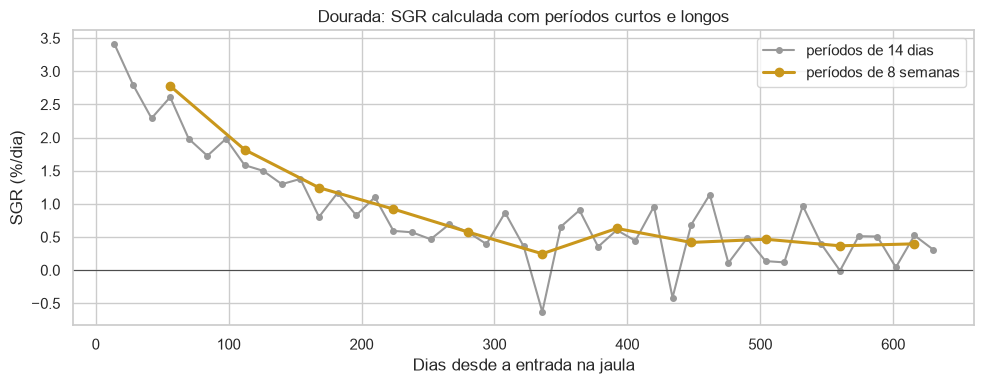

Períodos de 14 dias com SGR negativa (o peixe 'encolheu'): 3
FCR mínimo e máximo em períodos de 14 dias: -540.5 e 13.5


In [5]:
dourada = registos[registos["especie"] == "dourada"]
por_14_dias = indicadores_por_periodo(dourada)
por_8_semanas = indicadores_por_periodo(agrupar_biometrias(dourada, cada=4))

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(por_14_dias["dia_fim"], por_14_dias["sgr"], "o-", color="0.6", markersize=4,
        label="períodos de 14 dias")
ax.plot(por_8_semanas["dia_fim"], por_8_semanas["sgr"], "o-", color=CORES["dourada"],
        linewidth=2.2, label="períodos de 8 semanas")
ax.axhline(0, color="0.3", linewidth=0.8)
ax.set_title("Dourada: SGR calculada com períodos curtos e longos")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("SGR (%/dia)")
ax.legend()
plt.tight_layout()
plt.show()

print("Períodos de 14 dias com SGR negativa (o peixe 'encolheu'):", (por_14_dias["sgr"] < 0).sum())
print("FCR mínimo e máximo em períodos de 14 dias:",
      round(por_14_dias["fcr"].min(), 1), "e", round(por_14_dias["fcr"].max(), 1))

Com períodos de 14 dias aparecem **SGR negativas** (como se os peixes encolhessem) e **FCR absurdos**. Os peixes não encolheram: é **erro de amostragem**.

Cada biometria pesa apenas 50 peixes. Como os peixes variam muito de tamanho (coeficiente de variação ≈ 30 %), a média da amostra tem um erro de cerca de $30\,\% / \sqrt{50} \approx 4\,\%$. Com peixes grandes, 14 dias de crescimento são também cerca de 4–7 % do peso, por isso o erro é do mesmo tamanho do sinal.

Isto também acontece nos dados reais, e é por isso que as explorações calculam o FCR por períodos longos (mensais, trimestrais ou por ciclo). Daqui em diante usamos **períodos de 8 semanas** (juntamos 4 biometrias seguidas, com `agrupar_biometrias`).

In [6]:
periodos = pd.concat(
    [indicadores_por_periodo(agrupar_biometrias(registos[registos["especie"] == e], cada=4))
         .assign(especie=e) for e in ESPECIES],
    ignore_index=True)
periodos.round(2)

,dia_inicio,dia_fim,peso_medio_g,temperatura_c,sgr,gpd,fcr,sobrevivencia_periodo,especie
0,0.0,56,3.1,17.90,2.78,0.21,2.02,97.14,dourada
1,56.0,112,14.7,21.40,1.82,0.46,2.09,97.63,dourada
2,112.0,168,40.7,22.82,1.24,0.73,2.37,97.26,dourada
3,168.0,224,81.7,20.95,0.92,0.99,2.11,97.42,dourada
4,224.0,280,136.9,17.40,0.58,0.93,2.35,97.35,dourada
5,280.0,336,189.0,15.22,0.25,0.50,5.08,97.23,dourada
6,336.0,392,217.1,16.22,0.63,1.64,1.57,97.27,dourada
7,392.0,448,308.9,19.62,0.42,1.46,2.65,97.03,dourada
8,448.0,504,390.5,22.50,0.47,2.08,2.37,97.58,dourada
9,504.0,560,507.1,22.33,0.37,2.07,2.82,97.32,dourada


### SGR: o peso e a temperatura

À esquerda, a SGR em função do peso do peixe. À direita, a mesma SGR em função da temperatura média de cada período.

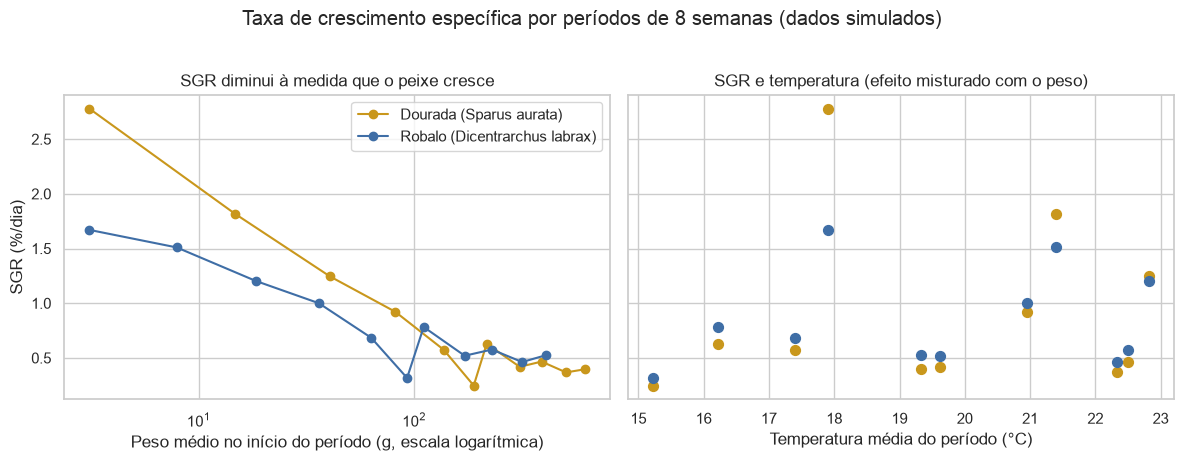

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for especie in ESPECIES:
    p = periodos[periodos["especie"] == especie]
    ax1.plot(p["peso_medio_g"], p["sgr"], "o-", color=CORES[especie], label=NOMES[especie])
    ax2.scatter(p["temperatura_c"], p["sgr"], color=CORES[especie], s=50, label=NOMES[especie])
ax1.set_xscale("log")
ax1.set_title("SGR diminui à medida que o peixe cresce")
ax1.set_xlabel("Peso médio no início do período (g, escala logarítmica)")
ax1.set_ylabel("SGR (%/dia)")
ax1.legend()
ax2.set_title("SGR e temperatura (efeito misturado com o peso)")
ax2.set_xlabel("Temperatura média do período (°C)")
fig.suptitle("Taxa de crescimento específica por períodos de 8 semanas (dados simulados)", y=1.02)
plt.tight_layout()
plt.savefig("../figures/02_sgr_peso_temperatura.png", dpi=150, bbox_inches="tight")
plt.show()

- **Efeito do peso (esquerda):** a SGR cai de forma acentuada ao longo do ciclo. É a consequência do expoente $b < 1$ na equação de crescimento: os juvenis crescem 2–3 % do peso por dia, os peixes comerciais menos de 0,5 %.
- **Efeito da temperatura:** a queda não é regular. Os pontos abaixo da tendência correspondem ao **inverno** (≈ 15–16 °C), quando o crescimento quase para, e há uma recuperação na primavera seguinte. No gráfico da direita a relação com a temperatura está misturada com o efeito do peso (os períodos quentes do segundo verão têm peixes muito maiores), por isso a temperatura sozinha não explica a SGR. Separar os dois efeitos é o objetivo dos cenários do notebook 04, em que mantemos a temperatura constante.

### GPD

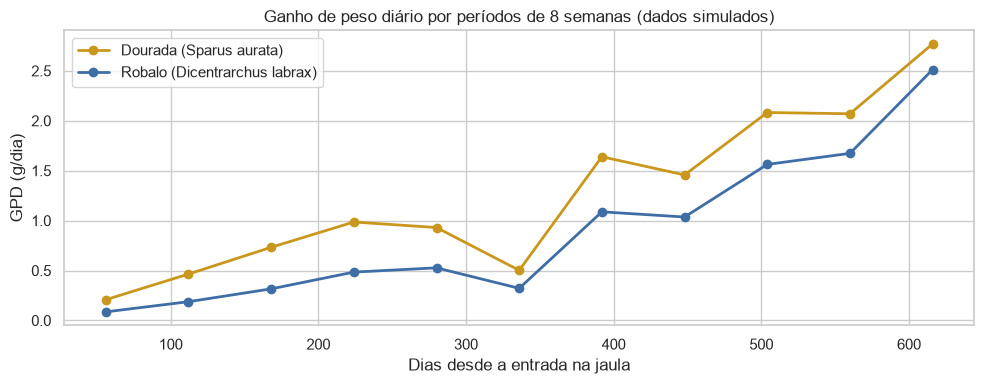

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
for especie in ESPECIES:
    p = periodos[periodos["especie"] == especie]
    ax.plot(p["dia_fim"], p["gpd"], "o-", color=CORES[especie], linewidth=2, label=NOMES[especie])
ax.set_title("Ganho de peso diário por períodos de 8 semanas (dados simulados)")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("GPD (g/dia)")
ax.legend()
plt.tight_layout()
plt.show()

Ao contrário da SGR, o **GPD aumenta** ao longo do ciclo: um peixe grande ganha mais gramas por dia, mesmo crescendo menos em percentagem. Também aqui se vê a quebra do inverno (por volta do dia 300). É por isto que a SGR é melhor para comparar peixes de tamanhos diferentes.

### FCR

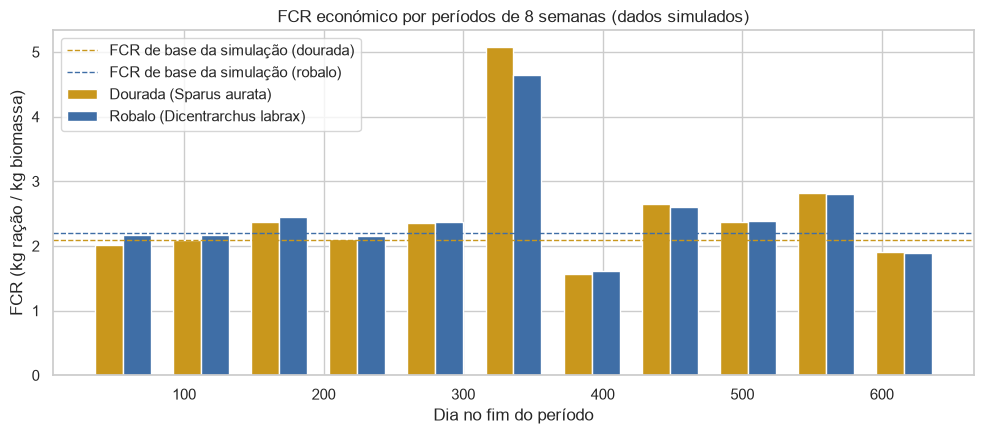

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
largura = 20
for i, especie in enumerate(ESPECIES):
    p = periodos[periodos["especie"] == especie]
    ax.bar(p["dia_fim"] + (i - 0.5) * largura, p["fcr"], width=largura,
           color=CORES[especie], label=NOMES[especie])
    ax.axhline(PARAMETROS[especie]["fcr"], color=CORES[especie], linestyle="--", linewidth=1,
               label=f"FCR de base da simulação ({especie})")
ax.set_title("FCR económico por períodos de 8 semanas (dados simulados)")
ax.set_xlabel("Dia no fim do período")
ax.set_ylabel("FCR (kg ração / kg biomassa)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("../figures/02_fcr.png", dpi=150)
plt.show()

- Na maior parte dos períodos o FCR económico fica **entre 1,6 e 2,8**, à volta do valor de base, com variação causada pelo erro de amostragem que ainda resta.
- O **pico no inverno** (FCR ≈ 5, dias 280–336) tem uma explicação simples: com a água fria os peixes quase não crescem, mas continuam a morrer ao mesmo ritmo. A biomassa perdida com os mortos pesa muito mais quando o ganho é pequeno, e o FCR económico dispara.
- **Atenção:** na realidade o FCR também piora no inverno por razões fisiológicas (digestão mais lenta). O nosso modelo **não inclui** esse efeito, porque a ração é sempre calculada com o mesmo FCR biológico. O pico vem apenas da mortalidade.
- Um período com FCR **abaixo** do esperado (ex.: 1,6 a seguir ao inverno) é, em parte, a compensação do erro de amostragem do período anterior.

### Sobrevivência

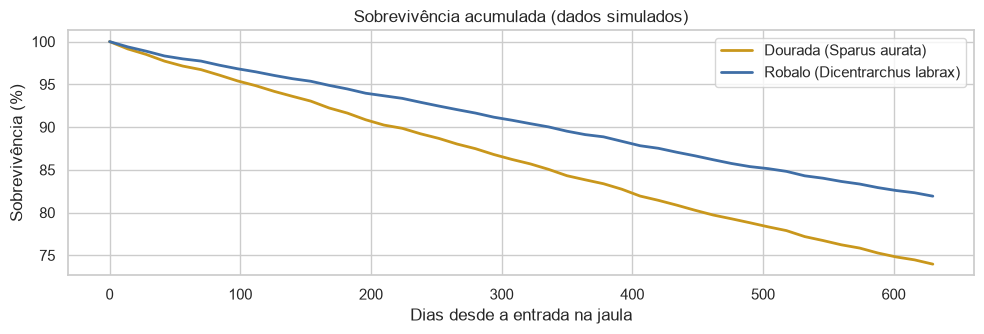

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for especie in ESPECIES:
    reg = registos[registos["especie"] == especie]
    ax.plot(reg["dia"], sobrevivencia(reg["n_peixes"].iloc[0], reg["n_peixes"]),
            color=CORES[especie], linewidth=2, label=NOMES[especie])
ax.set_title("Sobrevivência acumulada (dados simulados)")
ax.set_xlabel("Dias desde a entrada na jaula")
ax.set_ylabel("Sobrevivência (%)")
ax.legend()
plt.tight_layout()
plt.show()

A sobrevivência desce de forma regular porque a simulação usa uma probabilidade de morte **constante** por dia, calibrada para 80 % (dourada) e 85 % (robalo) no fim da duração de referência do ciclo (Muniesa et al., 2020). Numa exploração real a mortalidade concentra-se em episódios (doenças, manuseamento, temperaturas extremas), por isso a curva teria degraus.

## 2.4 Conclusões

| | Dourada | Robalo |
|---|---|---|
| SGR média até ao dia 448 | ≈ 1,1 %/dia | ≈ 1,0 %/dia |
| Peso ao dia 448 | ≈ 390 g | ≈ 230 g |
| FCR económico do ciclo | ≈ 2,3 | ≈ 2,3 |
| Sobrevivência ao dia 448 | ≈ 80 % | ≈ 87 % |

1. A **dourada cresce mais depressa** do que o robalo e o robalo tem melhor sobrevivência. Atenção: no fim do ciclo a SGR do robalo é ligeiramente mais alta (≈ 0,5 contra ≈ 0,4 %/dia), mas só porque o robalo é mais pequeno; **para o mesmo peso**, a dourada tem sempre a SGR mais alta (ex.: um peixe de 100 g a 20 °C: 0,85 contra 0,71 %/dia, notebook 01).
2. A **SGR desce com o peso** e **cai no inverno**. O GPD faz o contrário em relação ao peso. Por isso, para comparar crescimento, usa-se a SGR.
3. O **FCR económico** é mais alto do que o biológico e piora muito quando o crescimento é lento (inverno), porque a mortalidade continua.
4. Indicadores calculados com **biometrias muito próximas** são pouco fiáveis por causa do erro de amostragem. Períodos de 8 semanas dão valores estáveis.

**Limitações:** os dados são simulados; o modelo não inclui a piora fisiológica do FCR no inverno nem mortalidade em episódios.